# E0: Baseline RAG on RGB (prompt-based refusal)

Pipeline: RGB question + passages -> build context for a condition -> prompt -> small LLM -> score.

The E0 prompt follows the RGB setting: the model answers from the documents, and is told to reply with a **fixed refusal sentence** when the documents do not contain the answer, and a **fixed error sentence** when they contain factual errors. Score-based abstention methods (E1) are added in the second half of the notebook; they keep E0's answer and decide whether to abstain, on the same inputs.

Conditions:
1. **Noise** (irrelevant evidence): noise rate r = 0.0, 0.4, 0.8
2. **Incomplete** (insufficient evidence): r = 1.0, all passages are negatives; correct behaviour is to abstain
3. **Contradictory**: true passage + counterfactual passage + negatives (from `en_fact.json`)

Runtime: NTU CCDS TC1 cluster (1x V100 32GB), run as a Slurm job from `~/rag_project`.

In [1]:
# RGB data and Python packages are set up once on the TC1 head node (see setup steps),
# so this cell only checks they are in place.
import os
assert os.path.exists("RGB/data/en_refine.json"), "RGB not found - run: git clone https://github.com/chen700564/RGB.git in ~/rag_project"
print(sorted(os.listdir("RGB/data")))

['en.json', 'en_fact.json', 'en_int.json', 'en_refine.json', 'zh.json', 'zh_fact.json', 'zh_int.json', 'zh_refine.json']


## Datasets

We use the English portion of the RGB benchmark (Chen et al., 2024). Two files are used:

| File | Questions | Fields | Test case |
|---|---|---|---|
| `en_refine.json` | 300 | `query`, `answer`, `positive`, `negative` | **Noise robustness:** 5 passages with noise rate r ∈ {0.0, 0.4, 0.8} (share of negative passages); the answer is always present.<br>**Negative rejection:** r = 1.0, all 5 passages are negatives, so the model should refuse to answer. |
| `en_fact.json` | 100 | `query`, `answer`, `fakeanswer`, `positive`, `positive_wrong`, `negative` | **Counterfactual robustness:** context includes passages edited to state a false answer (`fakeanswer`); the model should detect the error and avoid the false answer. |

- `positive`: retrieved passages that contain the correct answer.
- `negative`: retrieved passages on a related topic that do not contain the answer.
- `positive_wrong`: copies of positive passages with the correct answer replaced by `fakeanswer`.

`en_refine.json` is the authors' corrected version of `en.json` (mislabelled passages removed, some answers fixed). The Chinese files and `en_int.json` (information integration) are not used, as they fall outside this project's scope.

In [2]:
import json, textwrap
import pandas as pd

DATA_DIR = "RGB/data"
FILES = {
    "en_refine.json": "Noise robustness (r = 0.0-0.8), negative rejection (r = 1.0)",
    "en_fact.json":   "Counterfactual robustness / contradictory evidence",
}
SNIP = 200   # characters shown per passage

def load_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]

def show_passages(label, passages, k=2):
    print(f"  {label} ({len(passages)} passages, showing {min(k, len(passages))}):")
    for p in passages[:k]:
        text = " ".join(p[:SNIP].split()) + ("..." if len(p) > SNIP else "")
        print(textwrap.fill(text, 100, initial_indent="    - ", subsequent_indent="      "))

data = {f: load_jsonl(f"{DATA_DIR}/{f}") for f in FILES}

# 1. Summary table
rows = []
for f, d in data.items():
    row = {"file": f, "used for": FILES[f], "questions": len(d),
           "fields": ", ".join(d[0].keys()),
           "avg positive": round(sum(len(x["positive"]) for x in d) / len(d), 1),
           "avg negative": round(sum(len(x["negative"]) for x in d) / len(d), 1)}
    if "positive_wrong" in d[0]:
        row["avg positive_wrong"] = round(sum(len(x["positive_wrong"]) for x in d) / len(d), 1)
    rows.append(row)
display(pd.DataFrame(rows).fillna("-"))

# 2. One example per file (change EXAMPLE_IDX to see another question)
EXAMPLE_IDX = 0
for f, d in data.items():
    x = d[EXAMPLE_IDX]
    print("=" * 100)
    print(f"{f}   (example id {x['id']})")
    print("=" * 100)
    print(f"  query:  {x['query']}")
    print(f"  answer: {x['answer']}")
    if "fakeanswer" in x:
        print(f"  fakeanswer: {x['fakeanswer']}")
    show_passages("positive", x["positive"])
    if "positive_wrong" in x:
        show_passages("positive_wrong", x["positive_wrong"])
    show_passages("negative", x["negative"])
    print()

/tmp/ipykernel_3277264/1369559934.py:33: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.DataFrame(rows).fillna("-"))


,file,used for,questions,fields,avg positive,avg negative,avg positive_wrong
0,en_refine.json,"Noise robustness (r = 0.0-0.8), negative rejec...",300,"id, query, answer, positive, negative",8.4,18.2,-
1,en_fact.json,Counterfactual robustness / contradictory evid...,100,"id, query, answer, fakeanswer, positive_wrong,...",4.0,5.9,4.0


en_refine.json   (example id 0)
  query:  When is the premiere of 'Carole King & James Taylor: Just Call Out My Name'?
  answer: [['January 2 2022', 'Jan 2, 2022', 'Jan. 2, 2022', 'January 2, 2022', '2 January 2022', '2 Jan, 2022', '2 Jan., 2022', '2 January, 2022']]
  positive (5 passages, showing 2):
    - However, the concert tour took place in honor of the 40th anniversary. The two might have aged
      since they first performed together but neither Carole King nor James Taylor have lost a beat
      in all thes...
    - The concert film includes the following songs:(You Make Me Feel Like) A Natural WomanSomething
      in the Way She MovesSo Far AwayCarolina in My MindCountry RoadSmackwater JackWhere You Lead
      (lyrics chang...
  negative (15 passages, showing 2):
    - Feb 10, 2022 Runtime: 2h 0m Carole King...
    - Your Ticket Confirmation # is located under the header in your email that reads "Your Ticket
      Reservation Details". Just below that it reads "Ticket Confir

In [3]:
import json, random, re, os
import torch
import pandas as pd
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME  = "Qwen/Qwen2.5-3B-Instruct"  # Local LLM
N_PASSAGES  = 5     # Passages per question
SEED        = 42
N_QUESTIONS = None     # None = all; set e.g. 50 for a quick test run first
BATCH_SIZE  = 8
MAX_NEW_TOKENS = 64
OUT_DIR = os.path.expanduser("~/rag_project/results_v2")   # new folder: results_test holds outputs of the old plain prompt
os.makedirs(OUT_DIR, exist_ok=True)



/tc1home/FYP/meag0002/rag_project/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Refusal detection.
# An output counts as a refusal if it uses the fixed refusal sentence, or a common refusal phrase
# in the model's own words -- unless it is a HEDGE: refusal wording followed by a guess
# ("not explicitly stated ... however, it is likely X"). Hedges count as answers.
REFUSAL     = "I can not answer the question because of insufficient information in documents."
REFUSAL_KEY = "insufficient information"

REFUSAL_PHRASES = [
    REFUSAL_KEY, "can not answer", "cannot answer", "unable to answer",
    "cannot be answered", "cannot be determined", "cannot determine",
    "does not provide", "do not provide", "doesn't provide",
    "does not contain", "do not contain", "doesn't contain",
    "does not specify", "do not specify", "doesn't specify",
    "does not mention", "do not mention", "not mentioned",
    "no information", "no mention", "none of the provided documents", "none of the documents",
    "not explicitly", "not directly",
]

# words that signal the model goes on to guess an answer anyway
HEDGE_MARKERS = [
    "likely", "probably", "presumably", "possibly", "might", "suggest", "infer", "implied",
    "indicating", "as indicated", "assume", "speculat", "expected to", "would be", "would have", "though",
]


## 1. Load RGB

Each file is JSON Lines. `positive` = passages containing the answer, `negative` = retrieved passages that do not.
`en_fact.json` adds `positive_wrong` (passages edited to state `fakeanswer`).

In [5]:
def load_jsonl(path, n=None):
    with open(path) as f:
        data = [json.loads(line) for line in f if line.strip()]
    return data[:n] if n else data

def flatten(passages):
    # some RGB files store positives as a list of lists; flatten to a list of strings
    out = []
    for p in passages:
        out.extend(p if isinstance(p, list) else [p])
    return out

main = load_jsonl("RGB/data/en_refine.json", N_QUESTIONS)   #questions for noise robustness & negative rejection
fact = load_jsonl("RGB/data/en_fact.json", N_QUESTIONS)     #counterfactual questions
print(len(main), "main questions |", len(fact), "counterfactual questions")
# print(json.dumps({k: (v[:1] if isinstance(v, list) else v) for k, v in main[0].items()}, indent=2)[:1500])

300 main questions | 100 counterfactual questions


## 2. Build contexts for each condition

Shuffle passages with a fixed seed so (a) the gold passage position carries no signal and (b) your improved method later sees **exactly the same inputs**. The built contexts are saved to disk for reuse.

In [6]:
def build_noise_context(item, noise_rate, rng):
    pos, neg = flatten(item["positive"]), flatten(item["negative"])
    n_neg = round(N_PASSAGES * noise_rate)
    n_pos = N_PASSAGES - n_neg
    n_neg = min(n_neg, len(neg))
    n_pos = min(n_pos, len(pos))
    docs = pos[:n_pos] + neg[:n_neg]
    rng.shuffle(docs)
    return docs

def build_contradictory_context(item, rng, n_true=1, n_wrong=1):
    pos   = flatten(item["positive"])
    wrong = flatten(item["positive_wrong"])
    neg   = flatten(item["negative"])
    docs = pos[:n_true] + wrong[:n_wrong]
    docs += neg[: max(0, N_PASSAGES - len(docs))]
    rng.shuffle(docs)
    return docs

def make_examples(condition, noise_rate=None):
    rng = random.Random(SEED)
    examples = []
    if condition == "contradictory":
        for it in fact:
            examples.append({"id": it["id"], "query": it["query"], "answer": it["answer"],
                             "fakeanswer": it.get("fakeanswer"),
                             "docs": build_contradictory_context(it, rng)})
    else:
        for it in main:
            examples.append({"id": it["id"], "query": it["query"], "answer": it["answer"],
                             "docs": build_noise_context(it, noise_rate, rng)})
    return examples

CONDITIONS = {
    "noise_0.0":     make_examples("noise", 0.0),
    "noise_0.4":     make_examples("noise", 0.4),
    "noise_0.8":     make_examples("noise", 0.8),
    "incomplete":    make_examples("noise", 1.0),
    "contradictory": make_examples("contradictory"),
}
for name, ex in CONDITIONS.items():
    with open(f"{OUT_DIR}/inputs_{name}.jsonl", "w") as f:
        for e in ex:
            f.write(json.dumps(e) + "\n")
    print(f"{name:14s} {len(ex)} examples")

noise_0.0      300 examples
noise_0.4      300 examples
noise_0.8      300 examples
incomplete     300 examples
contradictory  100 examples


## 3. Prompt (E0)

The prompt numbers the passages, adds the question, and gives three instructions: answer if the documents contain the answer; otherwise reply with the fixed refusal sentence; if the documents contain errors, start with the fixed error sentence and give the correct answer. The refusal sentence is the same one that the E1 methods insert when they abstain (`REFUSAL` below).

In [7]:
SYSTEM = "You are an accurate and reliable assistant that answers questions using only the provided documents."

def format_docs(docs):
    # collapse runs of whitespace left over from web scraping (shorter prompts, faster generation)
    return "\n\n".join(f"[{i+1}] {' '.join(d.split())}" for i, d in enumerate(docs))

def build_prompt(query, docs):
    return (
            f"Documents:\n{format_docs(docs)}\n\n"
            f"Question: {query}\n\n"
            "Instructions:\n"
            "- If the documents contain the answer, reply with a short answer.\n"
            "- If the documents do not contain enough information to answer, reply exactly: "
            "\"I can not answer the question because of insufficient information in documents.\"\n"
            "- If the documents contain conflicting or incorrect information, start your reply with "
            "\"There are factual errors in the provided documents.\" and then give the correct answer."
        )

ex = CONDITIONS["noise_0.4"][0]
print(build_prompt(ex["query"], ex["docs"])[-700:])   # last part: question + instruction

y 2, 2022, at 9:00pm ET/PT on CNN. The film will be available on demand via cable/satellite systems, CNNgo platforms, and CNN mobile apps, beginning Monday, January 3, through Sunday, January 16.

Question: When is the premiere of 'Carole King & James Taylor: Just Call Out My Name'?

Instructions:
- If the documents contain the answer, reply with a short answer.
- If the documents do not contain enough information to answer, reply exactly: "I can not answer the question because of insufficient information in documents."
- If the documents contain conflicting or incorrect information, start your reply with "There are factual errors in the provided documents." and then give the correct answer.


## 4. Load the generator

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "left"          # required for batched generation with decoder-only models
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, dtype=torch.float16, device_map="auto"   # fp16: V100 has no bf16 support
)
model.eval()
print(torch.cuda.get_device_name(0), "|", round(torch.cuda.memory_allocated() / 1e9, 2), "GB used")

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/434 [00:00<03:26,  2.10it/s]

Loading weights:  15%|█▍        | 63/434 [00:00<00:02, 143.44it/s]

Loading weights:  23%|██▎       | 99/434 [00:00<00:02, 145.08it/s]

Loading weights:  29%|██▉       | 125/434 [00:01<00:02, 142.55it/s]

...

Loading weights:  89%|████████▉ | 387/434 [00:02<00:00, 163.28it/s]

Loading weights:  93%|█████████▎| 404/434 [00:02<00:00, 151.50it/s]

Loading weights:  99%|█████████▉| 431/434 [00:02<00:00, 179.68it/s]

Loading weights: 100%|██████████| 434/434 [00:02<00:00, 150.51it/s]

Tesla V100-PCIE-32GB | 6.17 GB used


In [9]:
@torch.no_grad()
def generate(prompts):
    outputs = []
    for i in tqdm(range(0, len(prompts), BATCH_SIZE)):
        batch = prompts[i:i + BATCH_SIZE]
        texts = [tokenizer.apply_chat_template(
                    [{"role": "system", "content": SYSTEM}, {"role": "user", "content": p}],
                    tokenize=False, add_generation_prompt=True) for p in batch]
        enc = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                             pad_token_id=tokenizer.pad_token_id)
        new_tokens = out[:, enc["input_ids"].shape[1]:]   # strip the prompt
        outputs.extend(tokenizer.batch_decode(new_tokens, skip_special_tokens=True))
    return [o.strip() for o in outputs]

## 5. Scoring (RGB rules)

RGB's `answer` can be nested: the outer list holds parts that are **all** required; an inner list holds alternatives where **any one** counts. Matching is case-insensitive substring matching.

- **Refusal:** the fixed refusal sentence, or a common refusal phrase in the model's own words (`REFUSAL_PHRASES`).
- **Hedge:** refusal wording followed by a guess (`HEDGE_MARKERS`, e.g. "not explicitly stated ... however, it is likely X"). Hedges count as **answers**, not refusals.
- **Noise and contradictory:** accuracy (the output contains the gold answer). A refusal is simply not correct.
- **Incomplete:** rejection rate (share of outputs that use the refusal sentence).

In [10]:
def contains_answer(pred, answer):
    pred = pred.lower()
    if isinstance(answer, str):
        answer = [answer]
    for part in answer:
        alts = part if isinstance(part, list) else [part]
        if not any(str(a).lower() in pred for a in alts):
            return False
    return True

def is_hedge(pred):
    p = pred.lower()
    return any(x in p for x in REFUSAL_PHRASES) and any(h in p for h in HEDGE_MARKERS)

def is_rejection(pred):
    p = pred.lower()
    if REFUSAL_KEY in p:                              # the instructed sentence always counts
        return True
    if not any(x in p for x in REFUSAL_PHRASES):      # no refusal wording -> an answer
        return False
    return not is_hedge(pred)                          # refusal wording, but not followed by a guess

def score(name, examples, preds):
    rows = []
    for e, p in zip(examples, preds):
        rows.append({"id": e["id"], "query": e["query"], "pred": p,
                     "correct": contains_answer(p, e["answer"]),
                     "rejected": is_rejection(p),
                     "hedge": is_hedge(p) and REFUSAL_KEY not in p.lower()})
    
    df = pd.DataFrame(rows)
    df["rejected"] = df.rejected & ~df.correct          # a refusal that contains the answer counts as correct
    df["wrong"]    = ~df.correct & ~df.rejected

    if name == "incomplete":
        summary = {"rejection_rate": df.rejected.mean()}
    else:   # noise_* and contradictory
        summary = {"accuracy": df.correct.mean(),
                   "rejection_rate": df.rejected.mean(),
                   "wrong_answer": df.wrong.mean()}
    return df, summary

## 6. Run E0 on all conditions

`run_method` generates, scores and saves predictions for one method into its own folder (`OUT_DIR/<method>/`). It is reused by the E1 methods below.

If a prediction file already exists with the right number of rows, it is loaded and rescored instead of regenerated, so a disconnected Colab session resumes where it stopped. **Delete the folder to force a rerun** (e.g. after changing a prompt).

In [11]:
def run_method(method, build_prompt_fn):
    mdir = f"{OUT_DIR}/{method}"
    os.makedirs(mdir, exist_ok=True)
    summaries = {}
    for name, examples in CONDITIONS.items():
        print(f"\n=== {method} | {name} ===")
        path = f"{mdir}/preds_{name}.jsonl"
        preds = None
        if os.path.exists(path):
            old = pd.read_json(path, lines=True)
            if len(old) == len(examples):
                preds = old["pred"].fillna("").tolist()
                print("loaded saved predictions")
        if preds is None:
            preds = generate([build_prompt_fn(e["query"], e["docs"]) for e in examples])
        df, summary = score(name, examples, preds)
        df.to_json(path, orient="records", lines=True)
        summaries[name] = summary
        print({k: round(v, 3) for k, v in summary.items()})
    return summaries

BASELINE = "E0_refusal"
E0_summaries = run_method(BASELINE, build_prompt)


=== E0_refusal | noise_0.0 ===
loaded saved predictions
{'accuracy': np.float64(0.977), 'rejection_rate': np.float64(0.007), 'wrong_answer': np.float64(0.017)}

=== E0_refusal | noise_0.4 ===
loaded saved predictions
{'accuracy': np.float64(0.973), 'rejection_rate': np.float64(0.013), 'wrong_answer': np.float64(0.013)}

=== E0_refusal | noise_0.8 ===
loaded saved predictions
{'accuracy': np.float64(0.82), 'rejection_rate': np.float64(0.127), 'wrong_answer': np.float64(0.053)}

=== E0_refusal | incomplete ===
loaded saved predictions
{'rejection_rate': np.float64(0.84)}

=== E0_refusal | contradictory ===
loaded saved predictions
{'accuracy': np.float64(0.52), 'rejection_rate': np.float64(0.36), 'wrong_answer': np.float64(0.12)}


In [12]:
E0_results = pd.DataFrame(E0_summaries).T.round(3)
E0_results.to_csv(f"{OUT_DIR}/{BASELINE}/summary.csv")
E0_results.fillna("")   # blank = metric not used for that condition

/tmp/ipykernel_3277264/3720385599.py:3: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  E0_results.fillna("")   # blank = metric not used for that condition


,accuracy,rejection_rate,wrong_answer
noise_0.0,0.977,0.007,0.017
noise_0.4,0.973,0.013,0.013
noise_0.8,0.82,0.127,0.053
incomplete,,0.840,
contradictory,0.52,0.360,0.12


## 7. Inspect E0 failures

Look at real outputs before moving on: incomplete questions where the model did not use the refusal sentence, and contradictory questions it got wrong.

In [13]:
def show_failures(method, k=10):
    mdir = f"{OUT_DIR}/{method}"
    inc = pd.read_json(f"{mdir}/preds_incomplete.jsonl", lines=True)
    print(f"[{method}] Incomplete: did not use the refusal sentence ({(~inc.rejected).sum()} of {len(inc)}):")
    display(inc[~inc.rejected][["query", "pred"]].head(k))

    con = pd.read_json(f"{mdir}/preds_contradictory.jsonl", lines=True)
    print(f"[{method}] Contradictory: wrong answer ({(~con.correct).sum()} of {len(con)}):")
    display(con[~con.correct][["query", "pred"]].head(k))

show_failures(BASELINE)


[E0_refusal] Incomplete: did not use the refusal sentence (48 of 300):

,query,pred
2,Who won the 2022 Citrus Bowl?,The winner of the 2022 Citrus Bowl was New Mex...
23,Who won women's 500m speed skating at the 2022...,There are factual errors in the provided docum...
38,What is the weight of the Surface Laptop SE?,The weight of the Surface Laptop SE is 2.79 lb...
40,What happened at the Academy Awards involving ...,Will Smith slapped Chris Rock during Will Smit...
41,When did Apple M2 chip?,The M2 chip was released when Apple released i...
46,When is the final of the 2022 FIFA World Cup?,The final of the 2022 FIFA World Cup was betwe...
48,Who acquired Twitter?,There are factual errors in the provided docum...
52,Who won the women's singles Australian Open 2023?,Sabalenka won the women's singles Australian O...
55,Who won the women's singles French Open 2022?,There are factual errors in the provided docum...
59,Who won the men's singles French Open 2023?,I can answer the question because of sufficien...


[E0_refusal] Contradictory: wrong answer (48 of 100):


,query,pred
2,Who acquired Instagram?,There are factual errors in the provided docum...
7,Who won the men's singles Wimbledon in 2013?,I can not answer the question because of insuf...
9,Who won the men's singles U.S. Open in 2020?,There are factual errors in the provided docum...
10,Who won the women's singles U.S. Open in 2019?,There are factual errors in the provided docum...
11,Who won the men's singles U.S. Open 2021?,Rafael Nadal defeated Novak Djokovic in the me...
12,What was Tesla's revenue in Q1 2021?,I can not answer the question because of insuf...
16,Who acquired 20th Century Fox?,I can not answer the question because of insuf...
22,When was xenoblade chronicles 2 released?,I can not answer the question because of insuf...
23,When was xenoblade chronicles X released in Ja...,I can not answer the question because of insuf...
33,What is the premiere date of Grey's Anatomy Se...,"Dec 14, 2020"


# E1: Abstention baselines

Each method decides whether to keep E0's output or **abstain** (replace it with the fixed refusal sentence). All methods run on the same five conditions (same inputs as E0, loaded from `CONDITIONS`) and are scored with the same functions, so results are directly comparable with E0 and with each other.

| Method | Signal used to abstain | Output |
|---|---|---|
| **E1a Entropy / log-probability** | Low average token log-probability of the generated answer | A score; abstain below a threshold |
| **E1b Sampling agreement** | Agreement across several sampled answers; low agreement = abstain | A score; abstain below a threshold |
| **E1c LLM judge** | A separate prompt asking whether the documents contain enough information to answer; uses P("yes") | A score; abstain below a threshold |

What to compare across methods:
- **incomplete:** rejection rate (higher is better)
- **noise_*:** accuracy (abstaining when the answer *was* present lowers it)
- **contradictory:** accuracy

Score-based methods (E1a–E1c) are also compared on an accuracy–coverage curve by sweeping the threshold.

## Score-based methods (E1a–E1c): shared setup

E1a–E1c do **not** generate new answers. They keep E0's answer and attach a confidence score to it. A threshold τ turns the score into a decision: answer with E0's answer if score ≥ τ, otherwise abstain.

**Calibration / test split.** τ must not be tuned on the questions it is evaluated on. Questions are split by id: 30% for choosing τ (calibration), 70% for reporting (test). The same split is used for every method, including E0 in the final comparison.

**Choosing τ.** τ is the value that maximises the *balanced score* on the calibration split:

$$\text{balanced} = \tfrac{1}{2}\big(\text{mean accuracy over noise}_{0.0,0.4,0.8} + \text{rejection rate on incomplete}\big)$$

so answering correctly when evidence exists and abstaining when it doesn't count equally. Contradictory questions are not used for choosing τ; they are reported separately.

**Threshold-free view.** Each method also gets an accuracy–coverage curve and an AUROC (how well the score separates E0 answers that are right from ones that are wrong), both on the test split.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ANSWERABLE = ["noise_0.0", "noise_0.4", "noise_0.8"]
POOL       = ANSWERABLE + ["incomplete"]          # used for curves and threshold choice
CALIB_FRAC = 0.3

# E0 predictions, aligned with CONDITIONS
E0_PREDS = {}
for name, examples in CONDITIONS.items():
    df = pd.read_json(f"{OUT_DIR}/{BASELINE}/preds_{name}.jsonl", lines=True)
    assert len(df) == len(examples), f"E0 predictions for {name} missing or incomplete - run E0 first"
    E0_PREDS[name] = df["pred"].fillna("").astype(str).tolist()

# calibration / test split by question id (same split for every method)
_rng = random.Random(SEED)
_main_ids = sorted({e["id"] for e in CONDITIONS["incomplete"]})
_fact_ids = sorted({e["id"] for e in CONDITIONS["contradictory"]})
CALIB_IDS = {
    "main": set(_rng.sample(_main_ids, int(CALIB_FRAC * len(_main_ids)))),
    "fact": set(_rng.sample(_fact_ids, int(CALIB_FRAC * len(_fact_ids)))),
}
def in_split(name, qid, split):
    calib = CALIB_IDS["fact" if name == "contradictory" else "main"]
    return (qid in calib) == (split == "calib")

print(f"calibration: {len(CALIB_IDS['main'])} main + {len(CALIB_IDS['fact'])} counterfactual questions; rest = test")

calibration: 90 main + 30 counterfactual questions; rest = test


In [15]:
# ---------- model helpers (left padding + explicit position ids, as in generation) ----------
def chat_text(prompt):
    return tokenizer.apply_chat_template(
        [{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}],
        tokenize=False, add_generation_prompt=True)

def left_pad(seqs):
    L = max(len(s) for s in seqs)
    ids  = torch.full((len(seqs), L), tokenizer.pad_token_id, dtype=torch.long)
    mask = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, L - len(s):] = torch.tensor(s)
        mask[i, L - len(s):] = 1
    return ids.to(model.device), mask.to(model.device)

@torch.no_grad()
def forward_last(ids, mask, keep):
    # logits for the last `keep` positions only (full-vocab logits for every position would not fit in memory)
    pos = (mask.cumsum(-1) - 1).clamp(min=0)
    try:
        out = model(input_ids=ids, attention_mask=mask, position_ids=pos, use_cache=False, logits_to_keep=keep)
    except TypeError:   # older transformers
        out = model(input_ids=ids, attention_mask=mask, position_ids=pos, use_cache=False, num_logits_to_keep=keep)
    return out.logits[:, -keep:].float()

def cached(path, n, compute):
    # reuse saved results if they exist and have the right length (lets an interrupted run resume)
    if os.path.exists(path):
        df = pd.read_json(path, lines=True)
        if len(df) == n:
            print("loaded saved results")
            return df.to_dict("records")
    rows = compute()
    pd.DataFrame(rows).to_json(path, orient="records", lines=True)
    return rows

In [16]:
# ---------- evaluation helpers ----------
def apply_threshold(scores, tau):
    # keep E0's answer if score >= tau, otherwise abstain
    return {name: [p if s >= tau else REFUSAL for p, s in zip(E0_PREDS[name], scores[name])]
            for name in CONDITIONS}

def evaluate(final_preds, split):
    out = {}
    for name, examples in CONDITIONS.items():
        idx = [i for i, e in enumerate(examples) if in_split(name, e["id"], split)]
        _, out[name] = score(name, [examples[i] for i in idx], [final_preds[name][i] for i in idx])
    return out

def balanced(summ):
    noise_acc = np.mean([summ[n]["accuracy"] for n in ANSWERABLE])
    return (noise_acc + summ["incomplete"]["rejection_rate"]) / 2

def choose_threshold(scores):
    calib = [s for name in POOL for e, s in zip(CONDITIONS[name], scores[name]) if in_split(name, e["id"], "calib")]
    candidates = [-np.inf] + list(np.unique(np.quantile(calib, np.linspace(0, 1, 101))))
    best = max(candidates, key=lambda t: balanced(evaluate(apply_threshold(scores, t), "calib")))
    return float(best)

def pool_table(scores, preds=None, split="test"):
    # one row per test example in the POOL: score, whether the answer was given, whether it is correct
    preds = preds or E0_PREDS
    rows = []
    for name in POOL:
        for i, e in enumerate(CONDITIONS[name]):
            if not in_split(name, e["id"], split):
                continue
            p = preds[name][i]
            refused = is_rejection(p)
            ok = (name != "incomplete") and (not refused) and contains_answer(p, e["answer"])   # answering an incomplete question is always wrong
            rows.append({"score": scores[name][i] if scores else np.nan, "refused": refused, "ok": ok})
    return pd.DataFrame(rows)

def coverage_curve(scores):
    t = pool_table(scores)
    pts = []
    for tau in [-np.inf] + sorted(t.score.unique()):
        answered = (~t.refused) & (t.score >= tau)
        if answered.sum() == 0:
            continue
        pts.append((answered.mean(), (answered & t.ok).sum() / answered.sum()))
    return np.array(pts)

def auroc(scores):
    t = pool_table(scores)
    t = t[~t.refused]
    return roc_auc_score(t.ok, t.score) if t.ok.nunique() == 2 else np.nan

def single_point(preds):
    t = pool_table(None, preds)
    answered = ~t.refused
    return answered.mean(), (answered & t.ok).sum() / max(answered.sum(), 1)

def summary_row(summ):
    return {
        "acc noise_0.0":       summ["noise_0.0"]["accuracy"],
        "acc noise_0.4":       summ["noise_0.4"]["accuracy"],
        "acc noise_0.8":       summ["noise_0.8"]["accuracy"],
        "rej noise_0.8":       summ["noise_0.8"]["rejection_rate"],
        "rej incomplete":      summ["incomplete"]["rejection_rate"],
        "acc contradictory":   summ["contradictory"]["accuracy"],
        "rej contradictory":   summ["contradictory"]["rejection_rate"],
        "wrong contradictory": summ["contradictory"]["wrong_answer"],
        "balanced":            balanced(summ),
    }

RESULTS = {}   # method -> dict with scores / tau / summary, filled in by each method below

def report(method, scores):
    tau = choose_threshold(scores)
    final = apply_threshold(scores, tau)
    summ = evaluate(final, "test")
    RESULTS[method] = {"scores": scores, "tau": tau, "summary": summ, "preds": final}
    for name, examples in CONDITIONS.items():   # save final decisions for failure analysis (E4)
        pd.DataFrame({"id": [e["id"] for e in examples], "score": scores[name], "pred": final[name],
                      "split": ["calib" if in_split(name, e["id"], "calib") else "test" for e in examples]}
                    ).to_json(f"{OUT_DIR}/{method}/final_{name}.jsonl", orient="records", lines=True)
    pair = pd.DataFrame({BASELINE: summary_row(evaluate(E0_PREDS, "test")),
                         method: summary_row(summ)}).T.round(3)
    print(f"{method}: tau = {tau:.4f} | AUROC = {auroc(scores):.3f}  (test split)")
    display(pair)

## E1a: Entropy / log-probability

E0's answer is fed back to the model after its prompt (teacher forcing), and one forward pass gives the probability the model assigned to each answer token. Two scores per answer:
- **mean log-probability** of the answer tokens (higher = more confident)
- **mean entropy** of the next-token distribution at each answer position (lower = more confident; the score is −entropy)

This costs one forward pass per question, no generation. Because the saved E0 answer is re-tokenised, token boundaries can differ slightly from the original generation; this has a negligible effect on the average.

In [17]:
@torch.no_grad()
def answer_confidence(prompts, answers):
    res = []
    for i in tqdm(range(0, len(prompts), BATCH_SIZE)):
        P = [tokenizer(chat_text(p), add_special_tokens=False).input_ids for p in prompts[i:i + BATCH_SIZE]]
        A = [tokenizer(a, add_special_tokens=False).input_ids[:MAX_NEW_TOKENS] or [tokenizer.eos_token_id]
             for a in answers[i:i + BATCH_SIZE]]
        ids, mask = left_pad([p + a for p, a in zip(P, A)])
        K = max(len(a) for a in A) + 1
        logp = torch.log_softmax(forward_last(ids, mask, K), dim=-1)   # (B, K, vocab)
        for b, a in enumerate(A):
            lp = logp[b, K - len(a) - 1 : K - 1]                         # positions that predict the answer tokens
            tok_lp = lp.gather(-1, torch.tensor(a, device=lp.device)[:, None]).squeeze(-1)
            ent = -(lp.exp() * lp).sum(-1)
            res.append({"mean_logprob": tok_lp.mean().item(), "mean_entropy": ent.mean().item()})
    return res

os.makedirs(f"{OUT_DIR}/E1a_logprob", exist_ok=True)
os.makedirs(f"{OUT_DIR}/E1a_entropy", exist_ok=True)
conf = {}
for name, examples in CONDITIONS.items():
    print(f"\n=== E1a | {name} ===")
    conf[name] = cached(f"{OUT_DIR}/E1a_logprob/confidence_{name}.jsonl", len(examples),
                        lambda: answer_confidence([build_prompt(e["query"], e["docs"]) for e in examples], E0_PREDS[name]))

E1a_logprob_scores = {n: [r["mean_logprob"] for r in rows] for n, rows in conf.items()}
E1a_entropy_scores = {n: [-r["mean_entropy"] for r in rows] for n, rows in conf.items()}


=== E1a | noise_0.0 ===
loaded saved results

=== E1a | noise_0.4 ===
loaded saved results

=== E1a | noise_0.8 ===
loaded saved results

=== E1a | incomplete ===
loaded saved results

=== E1a | contradictory ===
loaded saved results


In [18]:
report("E1a_logprob", E1a_logprob_scores)
report("E1a_entropy", E1a_entropy_scores)

E1a_logprob: tau = -0.1383 | AUROC = 0.822  (test split)


,acc noise_0.0,acc noise_0.4,acc noise_0.8,rej noise_0.8,rej incomplete,acc contradictory,rej contradictory,wrong contradictory,balanced
E0_refusal,0.981,0.976,0.819,0.148,0.829,0.5,0.357,0.143,0.877
E1a_logprob,0.948,0.914,0.700,0.271,0.910,0.3,0.614,0.086,0.882


E1a_entropy: tau = -0.2991 | AUROC = 0.864  (test split)


,acc noise_0.0,acc noise_0.4,acc noise_0.8,rej noise_0.8,rej incomplete,acc contradictory,rej contradictory,wrong contradictory,balanced
E0_refusal,0.981,0.976,0.819,0.148,0.829,0.500,0.357,0.143,0.877
E1a_entropy,0.957,0.948,0.757,0.214,0.890,0.343,0.557,0.100,0.889


## E1b: Sampling agreement

For each question, `N_SAMPLES` extra answers are sampled from the same E0 prompt (temperature 0.7). The score is the fraction of samples that **agree with E0's greedy answer**. Two answers agree if both are refusals, or neither is and their normalised token F1 is ≥ 0.5 (so "January 2, 2022" and "It premiered on January 2, 2022" agree).

This is the most expensive method: `N_SAMPLES` generations per question. Results are saved per condition, so an interrupted run resumes. To save time, lower `N_SAMPLES` to 3 or `MAX_NEW_TOKENS_SAMPLE` to 32.

In [19]:
import string
from collections import Counter

N_SAMPLES   = 5
TEMPERATURE = 0.7
TOP_P       = 0.95
SAMPLE_BATCH = 4                 # prompts per batch (x N_SAMPLES sequences); lower if you run out of GPU memory
MAX_NEW_TOKENS_SAMPLE = MAX_NEW_TOKENS
AGREE_F1 = 0.5

@torch.no_grad()
def sample_answers(prompts):
    outs = []
    for i in tqdm(range(0, len(prompts), SAMPLE_BATCH)):
        texts = [chat_text(p) for p in prompts[i:i + SAMPLE_BATCH]]
        enc = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
        out = model.generate(**enc, do_sample=True, temperature=TEMPERATURE, top_p=TOP_P,
                             num_return_sequences=N_SAMPLES, max_new_tokens=MAX_NEW_TOKENS_SAMPLE,
                             pad_token_id=tokenizer.pad_token_id)
        dec = tokenizer.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        for j in range(len(texts)):   # samples for one prompt are consecutive
            outs.append({"samples": [d.strip() for d in dec[j * N_SAMPLES:(j + 1) * N_SAMPLES]]})
    return outs

def normalize(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in string.punctuation)
    return [w for w in s.split() if w not in {"a", "an", "the"}]

def token_f1(a, b):
    a, b = normalize(a), normalize(b)
    common = sum((Counter(a) & Counter(b)).values())
    if common == 0:
        return 0.0
    p, r = common / len(a), common / len(b)
    return 2 * p * r / (p + r)

def agrees(sample, reference):
    if is_rejection(sample) or is_rejection(reference):
        return is_rejection(sample) and is_rejection(reference)
    return token_f1(sample, reference) >= AGREE_F1

os.makedirs(f"{OUT_DIR}/E1b_agreement", exist_ok=True)
samples = {}
for name, examples in CONDITIONS.items():
    print(f"\n=== E1b | {name} ===")
    torch.manual_seed(SEED)
    samples[name] = cached(f"{OUT_DIR}/E1b_agreement/samples_{name}.jsonl", len(examples),
                           lambda: sample_answers([build_prompt(e["query"], e["docs"]) for e in examples]))

E1b_scores = {name: [np.mean([agrees(s, ref) for s in row["samples"]])
                     for row, ref in zip(samples[name], E0_PREDS[name])]
              for name in CONDITIONS}


=== E1b | noise_0.0 ===
loaded saved results

=== E1b | noise_0.4 ===
loaded saved results

=== E1b | noise_0.8 ===
loaded saved results

=== E1b | incomplete ===


loaded saved results

=== E1b | contradictory ===


loaded saved results


In [20]:
report("E1b_agreement", E1b_scores)

E1b_agreement: tau = -inf | AUROC = 0.757  (test split)


,acc noise_0.0,acc noise_0.4,acc noise_0.8,rej noise_0.8,rej incomplete,acc contradictory,rej contradictory,wrong contradictory,balanced
E0_refusal,0.981,0.976,0.819,0.148,0.829,0.5,0.357,0.143,0.877
E1b_agreement,0.981,0.976,0.819,0.148,0.829,0.5,0.357,0.143,0.877


## E1c: LLM judge

The same Qwen model is asked a separate question about the same documents: *do they contain enough information to answer?* Instead of reading its text reply, one forward pass gives the probability of the first token being "Yes" vs "No":

$$\text{score} = \frac{P(\text{Yes})}{P(\text{Yes}) + P(\text{No})}$$

One forward pass per question, no generation. Note the judge looks at the documents only, not at E0's answer, so it targets insufficient evidence; it is not expected to catch contradictions, where the documents *do* appear to contain an answer.

In [21]:
JUDGE_INSTRUCTION = ("Do the documents contain enough information to answer the question? "
                     "Answer with only Yes or No.")

def build_judge_prompt(query, docs):
    return f"Documents:\n{format_docs(docs)}\n\nQuestion: {query}\n\n{JUDGE_INSTRUCTION}"

def first_token_ids(words):
    return sorted({tokenizer.encode(w, add_special_tokens=False)[0] for w in words})

YES_IDS = first_token_ids(["Yes", "yes", " Yes", " yes", "YES"])
NO_IDS  = first_token_ids(["No", "no", " No", " no", "NO"])
print("yes tokens:", tokenizer.convert_ids_to_tokens(YES_IDS), "| no tokens:", tokenizer.convert_ids_to_tokens(NO_IDS))

@torch.no_grad()
def judge_scores(prompts):
    res = []
    for i in tqdm(range(0, len(prompts), BATCH_SIZE)):
        P = [tokenizer(chat_text(p), add_special_tokens=False).input_ids for p in prompts[i:i + BATCH_SIZE]]
        ids, mask = left_pad(P)
        logp = torch.log_softmax(forward_last(ids, mask, 1)[:, -1], dim=-1)
        yes = torch.logsumexp(logp[:, YES_IDS], dim=-1)
        no  = torch.logsumexp(logp[:, NO_IDS], dim=-1)
        p_yes = torch.sigmoid(yes - no)
        res.extend({"p_yes": v} for v in p_yes.tolist())
    return res

os.makedirs(f"{OUT_DIR}/E1c_judge", exist_ok=True)
judge = {}
for name, examples in CONDITIONS.items():
    print(f"\n=== E1c | {name} ===")
    judge[name] = cached(f"{OUT_DIR}/E1c_judge/judge_{name}.jsonl", len(examples),
                         lambda: judge_scores([build_judge_prompt(e["query"], e["docs"]) for e in examples]))

E1c_scores = {n: [r["p_yes"] for r in rows] for n, rows in judge.items()}

yes tokens: ['ĠYes', 'Yes', 'yes', 'Ġyes', 'YES'] | no tokens: ['Ġno', 'no', 'ĠNo', 'No', 'NO']

=== E1c | noise_0.0 ===
loaded saved results

=== E1c | noise_0.4 ===
loaded saved results

=== E1c | noise_0.8 ===
loaded saved results

=== E1c | incomplete ===
loaded saved results

=== E1c | contradictory ===
loaded saved results


In [22]:
report("E1c_judge", E1c_scores)

E1c_judge: tau = 0.0044 | AUROC = 0.859  (test split)


,acc noise_0.0,acc noise_0.4,acc noise_0.8,rej noise_0.8,rej incomplete,acc contradictory,rej contradictory,wrong contradictory,balanced
E0_refusal,0.981,0.976,0.819,0.148,0.829,0.500,0.357,0.143,0.877
E1c_judge,0.962,0.933,0.724,0.248,0.919,0.143,0.786,0.071,0.896


## E1 final comparison (test split)

All methods on the same 70% test split. E0 has no threshold, so it appears as a single point on the curve; E1a–E1c use the τ chosen on the calibration split.

Reading the table:
- **acc noise_\*** / **acc contradictory**: output contains the gold answer (a refusal counts as not correct)
- **rej incomplete**: used the refusal sentence when no passage had the answer (higher is better)
- **balanced**: the τ-selection criterion, ½(mean noise accuracy + incomplete rejection rate)
- **coverage / sel. accuracy**: fraction of noise + incomplete questions answered, and accuracy on those answered
- **AUROC**: how well the score ranks right vs wrong E0 answers (score-based methods only; 0.5 = random)

In [23]:
rows = {}
r = summary_row(evaluate(E0_PREDS, "test"))
r["coverage"], r["sel. accuracy"] = single_point(E0_PREDS)
r["AUROC"], r["tau"] = np.nan, np.nan
rows[BASELINE] = r
for method, res in RESULTS.items():
    r = summary_row(res["summary"])
    r["coverage"], r["sel. accuracy"] = single_point(res["preds"])
    r["AUROC"], r["tau"] = auroc(res["scores"]), res["tau"]
    rows[method] = r

final_table = pd.DataFrame(rows).T.round(3)
final_table.to_csv(f"{OUT_DIR}/E1_final_comparison.csv")
final_table.fillna("")

/tmp/ipykernel_3277264/91250891.py:14: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  final_table.fillna("")


,acc noise_0.0,acc noise_0.4,acc noise_0.8,rej noise_0.8,rej incomplete,acc contradictory,rej contradictory,wrong contradictory,balanced,coverage,sel. accuracy,AUROC,tau
E0_refusal,0.981,0.976,0.819,0.148,0.829,0.500,0.357,0.143,0.877,0.748,0.925,,
E1a_logprob,0.948,0.914,0.700,0.271,0.910,0.300,0.614,0.086,0.882,0.674,0.951,0.822,-0.138
E1a_entropy,0.957,0.948,0.757,0.214,0.890,0.343,0.557,0.100,0.889,0.705,0.944,0.864,-0.299
E1b_agreement,0.981,0.976,0.819,0.148,0.829,0.500,0.357,0.143,0.877,0.748,0.925,0.757,-inf
E1c_judge,0.962,0.933,0.724,0.248,0.919,0.143,0.786,0.071,0.896,0.686,0.951,0.859,0.004


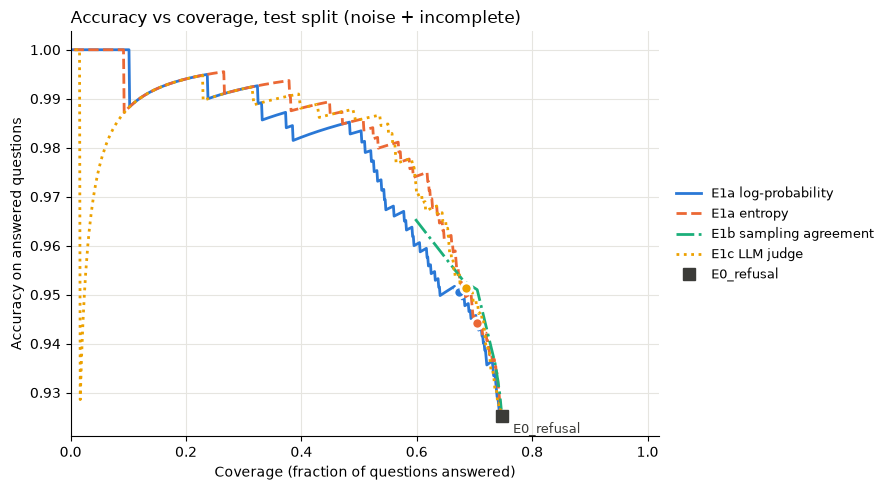

Filled circles = each method's operating point at its chosen tau.


In [24]:
# Accuracy-coverage on the test split (noise + incomplete pooled)
CURVES = [   # (method, label, colour, line style) - fixed colour order; line style is a second cue
    ("E1a_logprob",   "E1a log-probability",    "#2a78d6", "-"),
    ("E1a_entropy",   "E1a entropy",            "#eb6834", "--"),
    ("E1b_agreement", "E1b sampling agreement", "#1baf7a", "-."),
    ("E1c_judge",     "E1c LLM judge",          "#eda100", ":"),
]

fig, ax = plt.subplots(figsize=(9, 5))
for method, label, colour, ls in CURVES:
    if method not in RESULTS:
        continue
    pts = coverage_curve(RESULTS[method]["scores"])
    ax.plot(pts[:, 0], pts[:, 1], color=colour, linestyle=ls, linewidth=2, label=label)
    tau_pt = single_point(RESULTS[method]["preds"])   # operating point at the chosen tau
    ax.plot(*tau_pt, marker="o", markersize=8, color=colour, markeredgecolor="white", markeredgewidth=2)

x, y = single_point(E0_PREDS)
ax.plot(x, y, marker="s", markersize=9, color="#3b3b38", linestyle="none", label=BASELINE)
ax.annotate(BASELINE, (x, y), textcoords="offset points", xytext=(8, -12), fontsize=9, color="#3b3b38")

ax.set_xlabel("Coverage (fraction of questions answered)")
ax.set_ylabel("Accuracy on answered questions")
ax.set_title("Accuracy vs coverage, test split (noise + incomplete)", loc="left", fontsize=12)
ax.set_xlim(0, 1.02)
ax.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/E1_accuracy_coverage.png", dpi=200)
plt.show()
print("Filled circles = each method's operating point at its chosen tau.")